# 08 · M1.1 foundation — data-quality failures, signal reliability, snap-anchored NFL windows

**Status: PENDING USER EXECUTION.** This notebook was authored without being run. It computes nothing heavy: it **loads persisted outputs**, validates them against their contracts, shows the tables and figures, and holds interpretation placeholders.

Build the outputs first, from a terminal in the repo root (conda env `nfl`, `set NFL_BDB_DUCKDB_MEMORY=3GB`):

```
python -m pytest tests/test_m1_1_signal_integrity.py tests/test_m1_1_play_windows.py tests/test_m1_1_dq_failures.py tests/test_m1_1_signal_study.py tests/test_polars2_compat.py -q
python -m nflbdb.research.studies --only A0                     # exact DQ-failure drill-down
python -m nflbdb.research.studies --only A3 --sample-athletes 300 --skip-nfl-sample   # smoke → _sample
python -m nflbdb.research.studies --only A3                     # full (reads Study A flags)
python -m nflbdb.research.nfl_windows --seasons 2023 --limit-games 10                  # pilot → phase_03/_sample
python -m nflbdb.research.nfl_windows                           # full REG-season build
python -m nflbdb.research.nfl_windows --check
```

Restart the kernel after any code edit.

In [3]:
from pathlib import Path

import polars as pl
from IPython.display import Image, display

from nflbdb.data.config import Phase01Config, configure_runtime
from nflbdb.research.artifacts import ArtifactStore
from nflbdb.research.studies import dq_failures as A0, signal_reliability as A3
from nflbdb.research.studies.store import STUDY_DIRS, StudyStore

cfg = Phase01Config.load()
configure_runtime(cfg)
studies = StudyStore(cfg)                          # full-run study outputs (smoke runs live under _sample)
p03 = ArtifactStore(cfg, phase="phase_03")        # NFL window datasets + tables
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(16)
pl.Config.set_fmt_str_lengths(120)


def show_fig(study: str, name: str) -> None:
    p = studies.figure_dir(study) / f"{name}.png"
    display(Image(filename=str(p))) if p.is_file() else print(f"missing figure {cfg.paths.rel(p)} — run the study")


def show_p03_fig(name: str) -> None:
    p = p03.figures_dir / f"{name}.png"
    display(Image(filename=str(p))) if p.is_file() else print(f"missing figure {cfg.paths.rel(p)}")

## A0 · Phase 01 data-quality failures (exact drill-down)

Every FAIL / WARN / ERROR row of `reports/tables/data_quality_results.csv`, re-measured **exactly** (Phase 01 sampled tracking at 2 %). `classification` is a diagnostic hypothesis for review — not a verdict. Gate **G0** passes when no row has `blocking = true`, or the affected population is excluded reproducibly.

severity,check_id,phase01_mode,drilldown_mode,n_affected_rows,n_affected_trajectories,n_affected_athletes,n_affected_linked_athletes,classification,resolved_downstream,blocking
str,str,str,str,i64,i64,i64,i64,str,str,bool
"""MEDIUM""","""uniq:combine_tracking:event_id, nfl_id, time""","""sample 2.0% (finds issues, cannot prove absence)""","""exact""",64190,551,54,54,"""rule_error""","""yes""",false
"""CRITICAL""","""uniq:combine_tracking:event_id, nfl_id, attempt, time""","""sample 2.0% (finds issues, cannot prove absence)""","""exact""",64190,551,54,54,"""rule_error""","""yes""",false
"""MEDIUM""","""range:combine_tracking:s""","""sample 2.0% (finds issues, cannot prove absence)""","""exact""",0,0,0,0,"""rule_error""","""yes""",false
"""MEDIUM""","""range:combine_tracking:a""","""sample 2.0% (finds issues, cannot prove absence)""","""exact""",0,0,0,0,"""rule_error""","""yes""",false
"""HIGH""","""fk:game_tracking:game_id,play_id->player_play""","""sample 2.0% (finds issues, cannot prove absence)""","""exact""",14952,209,46,46,"""coverage_gap""","""no""",false
"""MEDIUM""","""fk:game_tracking:game_id,play_id,nfl_id->player_play""","""sample 2.0% (finds issues, cannot prove absence)""","""exact""",180858,2497,124,124,"""coverage_gap""","""no""",false
"""MEDIUM""","""trk:game:n_jumps""","""sample 2.0% of trajectories""","""exact (M1 trajectories)""",391,375,153,null,"""data_defect_handled""","""yes""",false


check_id,evidence,recommendation
str,str,str
"""uniq:combine_tracking:event_id, nfl_id, time""","""dup_rows=64,190, dup_keys=32,095, dup_rows_with_entity_type=0, dup_rows_player_only=0, silver duplicates on key+entity_t…","""Grain is incomplete: duplicates vanish when entity_type joins the key. Amend the check grain to include entity_type (sou…"
"""uniq:combine_tracking:event_id, nfl_id, attempt, time""","""dup_rows=64,190, dup_keys=32,095, dup_rows_with_entity_type=0, dup_rows_player_only=0, silver duplicates on key+entity_t…","""Grain is incomplete: duplicates vanish when entity_type joins the key. Amend the check grain to include entity_type (sou…"
"""range:combine_tracking:s""","""rows out of range=8,746 (min=12.51977158, max=25.79415639), of which athlete rows=0, M1 PLAYER frames with derived speed…","""Only non-athlete rows (e.g. BALL) exceed the range; ball speed is legitimately high. Restrict the plausibility check to …"
"""range:combine_tracking:a""","""rows out of range=264 (min=15.02245915, max=44.60728273), of which athlete rows=0, M1 PLAYER frames with derived accel_m…","""Only non-athlete rows (e.g. BALL) exceed the range; ball speed is legitimately high. Restrict the plausibility check to …"
"""fk:game_tracking:game_id,play_id->player_play""","""orphan keys=202; orphan plays with a ball_snap tag=202 of 202""","""Tracked keys without a player_play row have no play context (role, side, result). Keep them for role-agnostic kinematics…"
"""fk:game_tracking:game_id,play_id,nfl_id->player_play""","""orphan keys=2,497; orphan plays with a ball_snap tag=2,279 of 2,280; orphan player keys whose play IS in player_play=2,2…","""Tracked keys without a player_play row have no play context (role, side, result). Keep them for role-agnostic kinematics…"
"""trk:game:n_jumps""","""M1 n_jump_breaks: total=391, trajectories=375 of 314,944; same threshold (max_step_yds per nominal interval); M1 starts …","""Tracking glitch handled by M1 segmentation (a new segment starts at the break; the break is never differentiated). Frame…"


check_id,facet,level,n_keys,n_rows,n_trajectories,n_athletes
str,str,str,i64,i64,i64,i64
"""uniq:combine_tracking:event_id, nfl_id, time""","""row_kind""","""BALL""",null,32095,551,54
"""uniq:combine_tracking:event_id, nfl_id, time""","""row_kind""","""PLAYER""",null,32095,551,54
"""uniq:combine_tracking:event_id, nfl_id, attempt, time""","""row_kind""","""BALL""",null,32095,551,54
"""uniq:combine_tracking:event_id, nfl_id, attempt, time""","""row_kind""","""PLAYER""",null,32095,551,54
"""range:combine_tracking:s""","""row_kind""","""BALL""",null,8746,547,54
"""range:combine_tracking:s""","""m1_player_frames""","""vendor_out_of_range""",null,0,null,null
"""range:combine_tracking:s""","""m1_player_frames""","""derived_speed_also_out_of_range""",null,0,null,null
"""range:combine_tracking:a""","""row_kind""","""BALL""",null,264,49,34
"""range:combine_tracking:a""","""m1_player_frames""","""vendor_out_of_range""",null,0,null,null


blocking checks: []


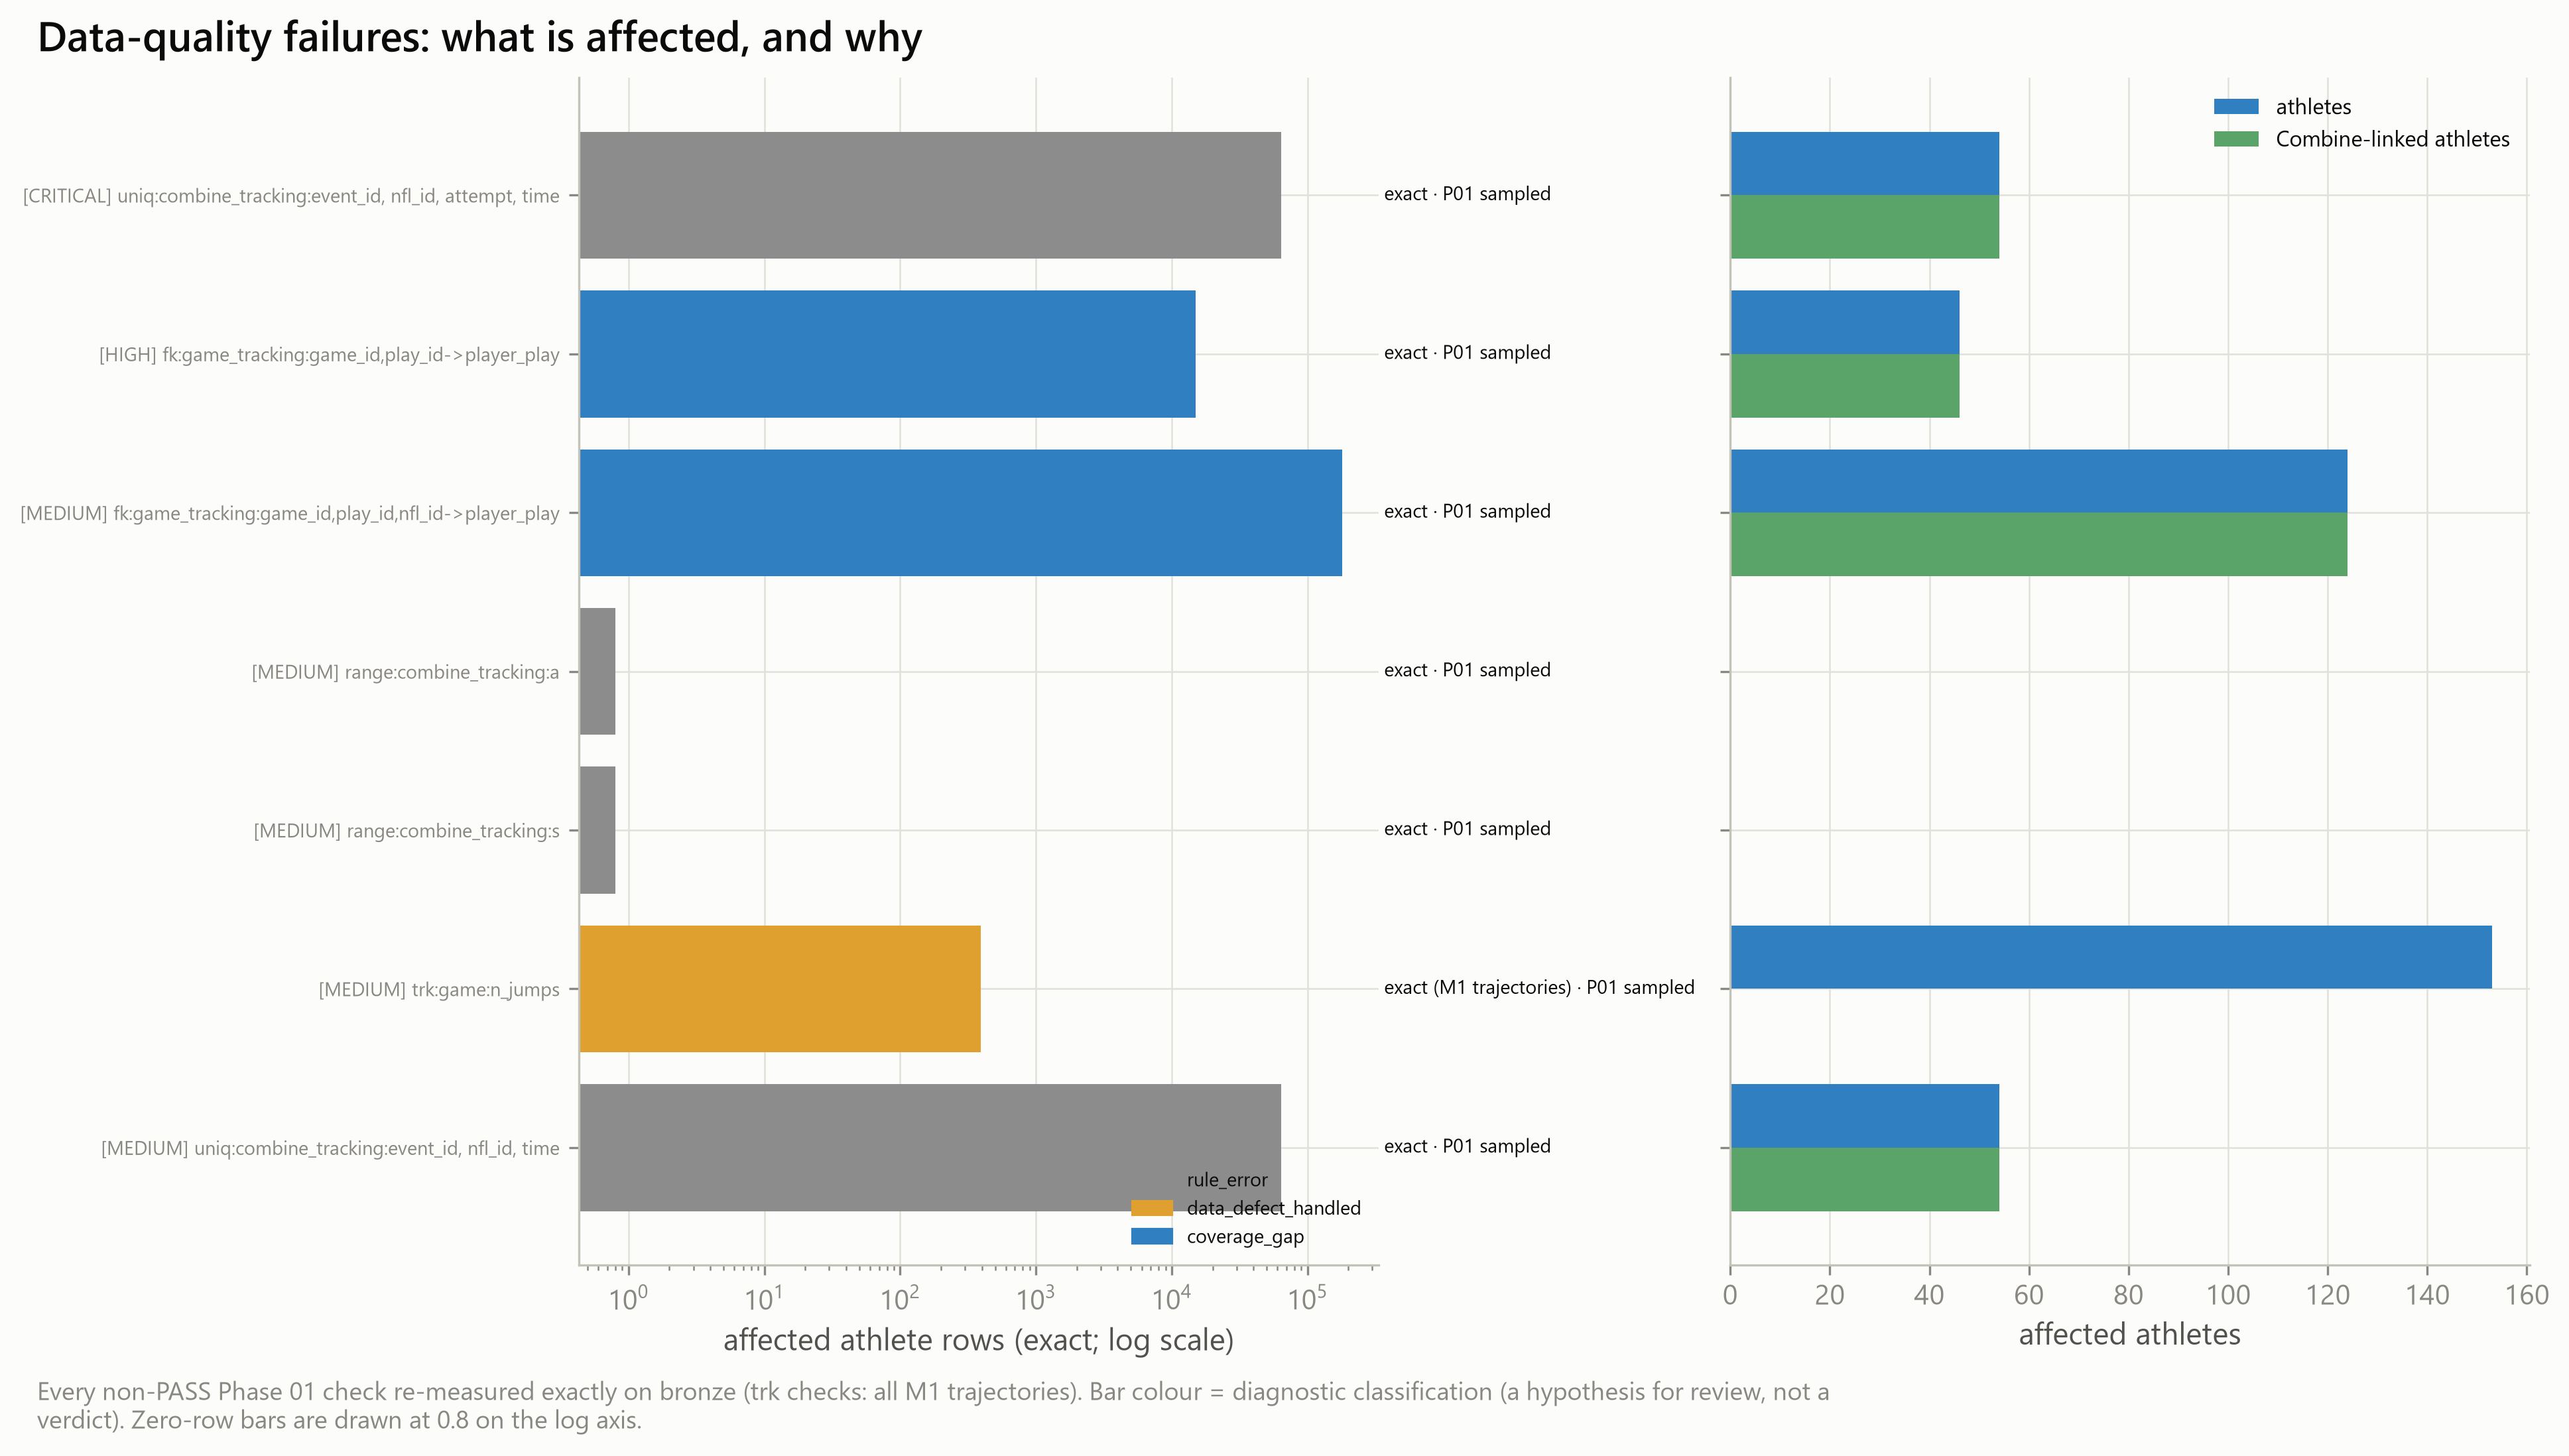

In [4]:
a0 = A0.DqFailureStudy(cfg, store=studies).load()          # conform() validates every contract
f = a0[A0.DQ_FAILURES.name]
display(f.select("severity", "check_id", "phase01_mode", "drilldown_mode", "n_affected_rows", "n_affected_trajectories",
                 "n_affected_athletes", "n_affected_linked_athletes", "classification", "resolved_downstream", "blocking"))
display(f.select("check_id", "evidence", "recommendation"))
display(a0[A0.BREAKDOWN.name])
print("blocking checks:", f.filter(pl.col("blocking"))["check_id"].to_list())
show_fig("A0", "A0_01_dq_failure_dashboard")

**Interpretation (fill after execution):**
- Combine key-uniqueness (CRITICAL): _expected `rule_error` if the BALL-row hypothesis holds — confirm `dup_rows_with_entity_type = 0`._
- Combine `s` / `a` range WARN: _BALL rows only? If PLAYER rows are affected, is the derived value also implausible?_
- game_tracking → player_play orphans: _how many Combine-linked athletes lose play context; season / season_type pattern; share with a snap tag._
- Decision on G0: _…_

## A3 · Derivative-signal reliability

Separates *signal* reliability (sampling, vendor residual, jerk roughness, heading definability, filter-boundary share) from *structural* validity. Three questions: (1) do peaks sit on SG filter-boundary frames more often than chance, (2) do tiers / quality metrics discriminate unreliable signals (AUC), (3) does signal roughness differ by cohort?

domain,stratum,peak,n_trajectories,n_athletes,share_in_boundary,boot_lower,boot_upper,expected_share,ratio_observed_expected,median_boundary_rel,p90_boundary_rel
str,str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64
"""combine""","""THREE_CONE_DRILL""","""peak_speed""",203,160,0.901478,0.846894,0.940014,0.0794,11.353658,0.0871,0.116426
"""combine""","""SKILL_DRILLS_OL""","""peak_speed""",910,121,0.845055,0.823305,0.867931,0.110565,7.643049,0.037264,0.119184
"""combine""","""SHORT_SHUTTLE""","""peak_speed""",223,170,0.816143,0.765644,0.865741,0.121173,6.735342,0.10111,0.181059
"""combine""","""FORTY_YARD_DASH""","""peak_abs_yaw_rate""",793,418,0.750315,0.723194,0.779114,0.115145,6.516246,0.45465,0.722375
"""combine""","""SKILL_DRILLS_DB""","""peak_speed""",1170,122,0.436752,0.40614,0.468906,0.077424,5.641029,0.0,0.039028
"""combine""","""SKILL_DRILLS_DL""","""peak_speed""",1007,114,0.436941,0.404868,0.470852,0.088134,4.957719,0.0,0.08701
"""combine""","""SKILL_DRILLS_LB""","""peak_speed""",37,4,0.324324,null,null,0.076257,4.253025,0.0,0.031179
"""combine""","""SKILL_DRILLS_TE""","""peak_speed""",438,42,0.310502,0.266055,0.347439,0.096572,3.215247,0.0,0.035048
"""combine""","""SKILL_DRILLS_TE""","""peak_abs_yaw_rate""",437,42,0.276888,0.228494,0.326619,0.096422,2.871633,0.0,0.462829


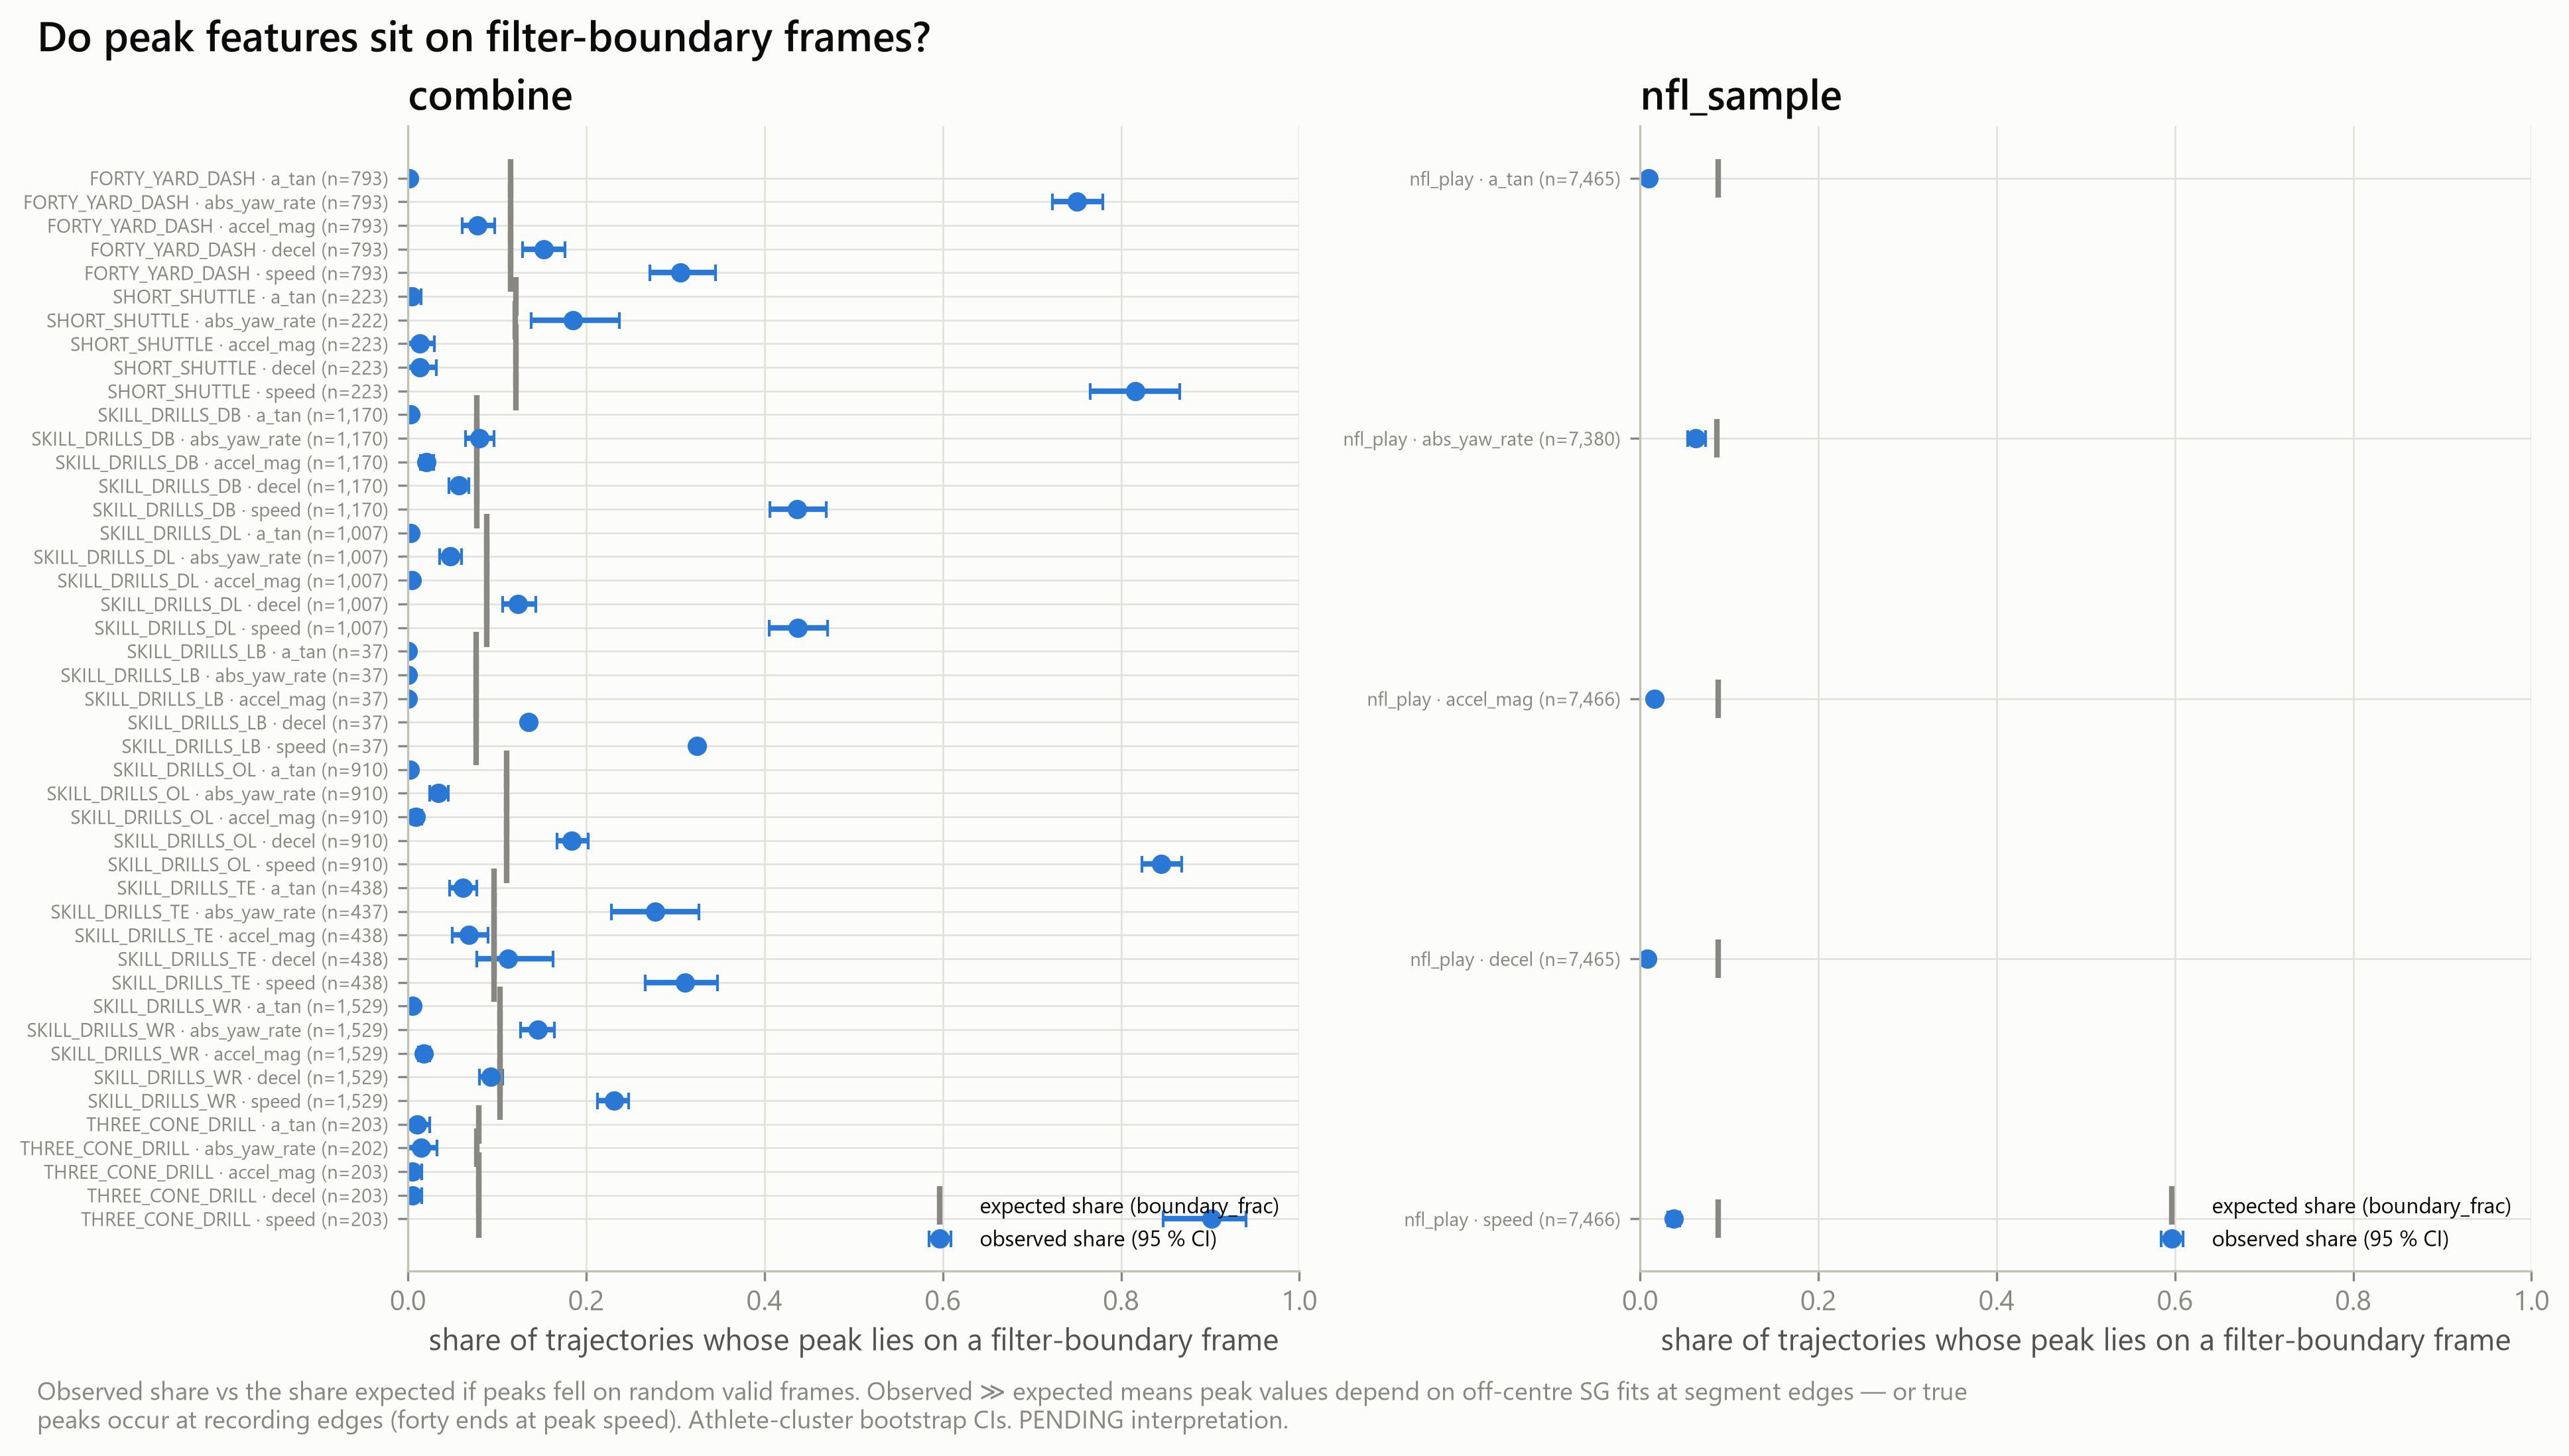

In [5]:
a3 = A3.SignalReliabilityStudy(cfg, store=studies).load()
display(a3[A3.BOUNDARY.name].sort("ratio_observed_expected", descending=True, nulls_last=True))
show_fig("A3", "A3_01_boundary_peak_share")

domain,predictor,target,shares_source,n_trajectories,n_positive,n_athletes,auc,ci_lower,ci_upper,result_status
str,str,str,bool,i64,i64,i64,f64,f64,f64,str
"""combine""","""speed_vendor_mad""","""jerk_high""",false,6310,320,510,0.821813,0.799611,0.841215,"""exploratory"""
"""combine""","""resid_rms_yds""","""jerk_high""",false,6310,320,510,0.724644,0.695075,0.751287,"""exploratory"""
"""combine""","""n_flagged_dims""","""jerk_high""",false,6310,320,510,0.630356,0.60419,0.657846,"""exploratory"""
"""combine""","""offgrid_rate""","""jerk_high""",false,6310,320,510,0.5,0.5,0.5,"""exploratory"""
"""combine""","""missing_frame_pct""","""jerk_high""",false,6310,320,510,0.5,0.5,0.5,"""exploratory"""
"""combine""","""dt_cv""","""jerk_high""",false,6310,320,510,0.5,0.5,0.5,"""exploratory"""
"""combine""","""unusable_frac""","""jerk_high""",false,6310,320,510,0.5,0.5,0.5,"""exploratory"""
"""combine""","""tier_not_A""","""jerk_high""",false,6310,320,510,0.499917,0.499744,0.5,"""exploratory"""
"""combine""","""boundary_frac""","""jerk_high""",false,6310,320,510,0.482201,0.454712,0.509608,"""exploratory"""


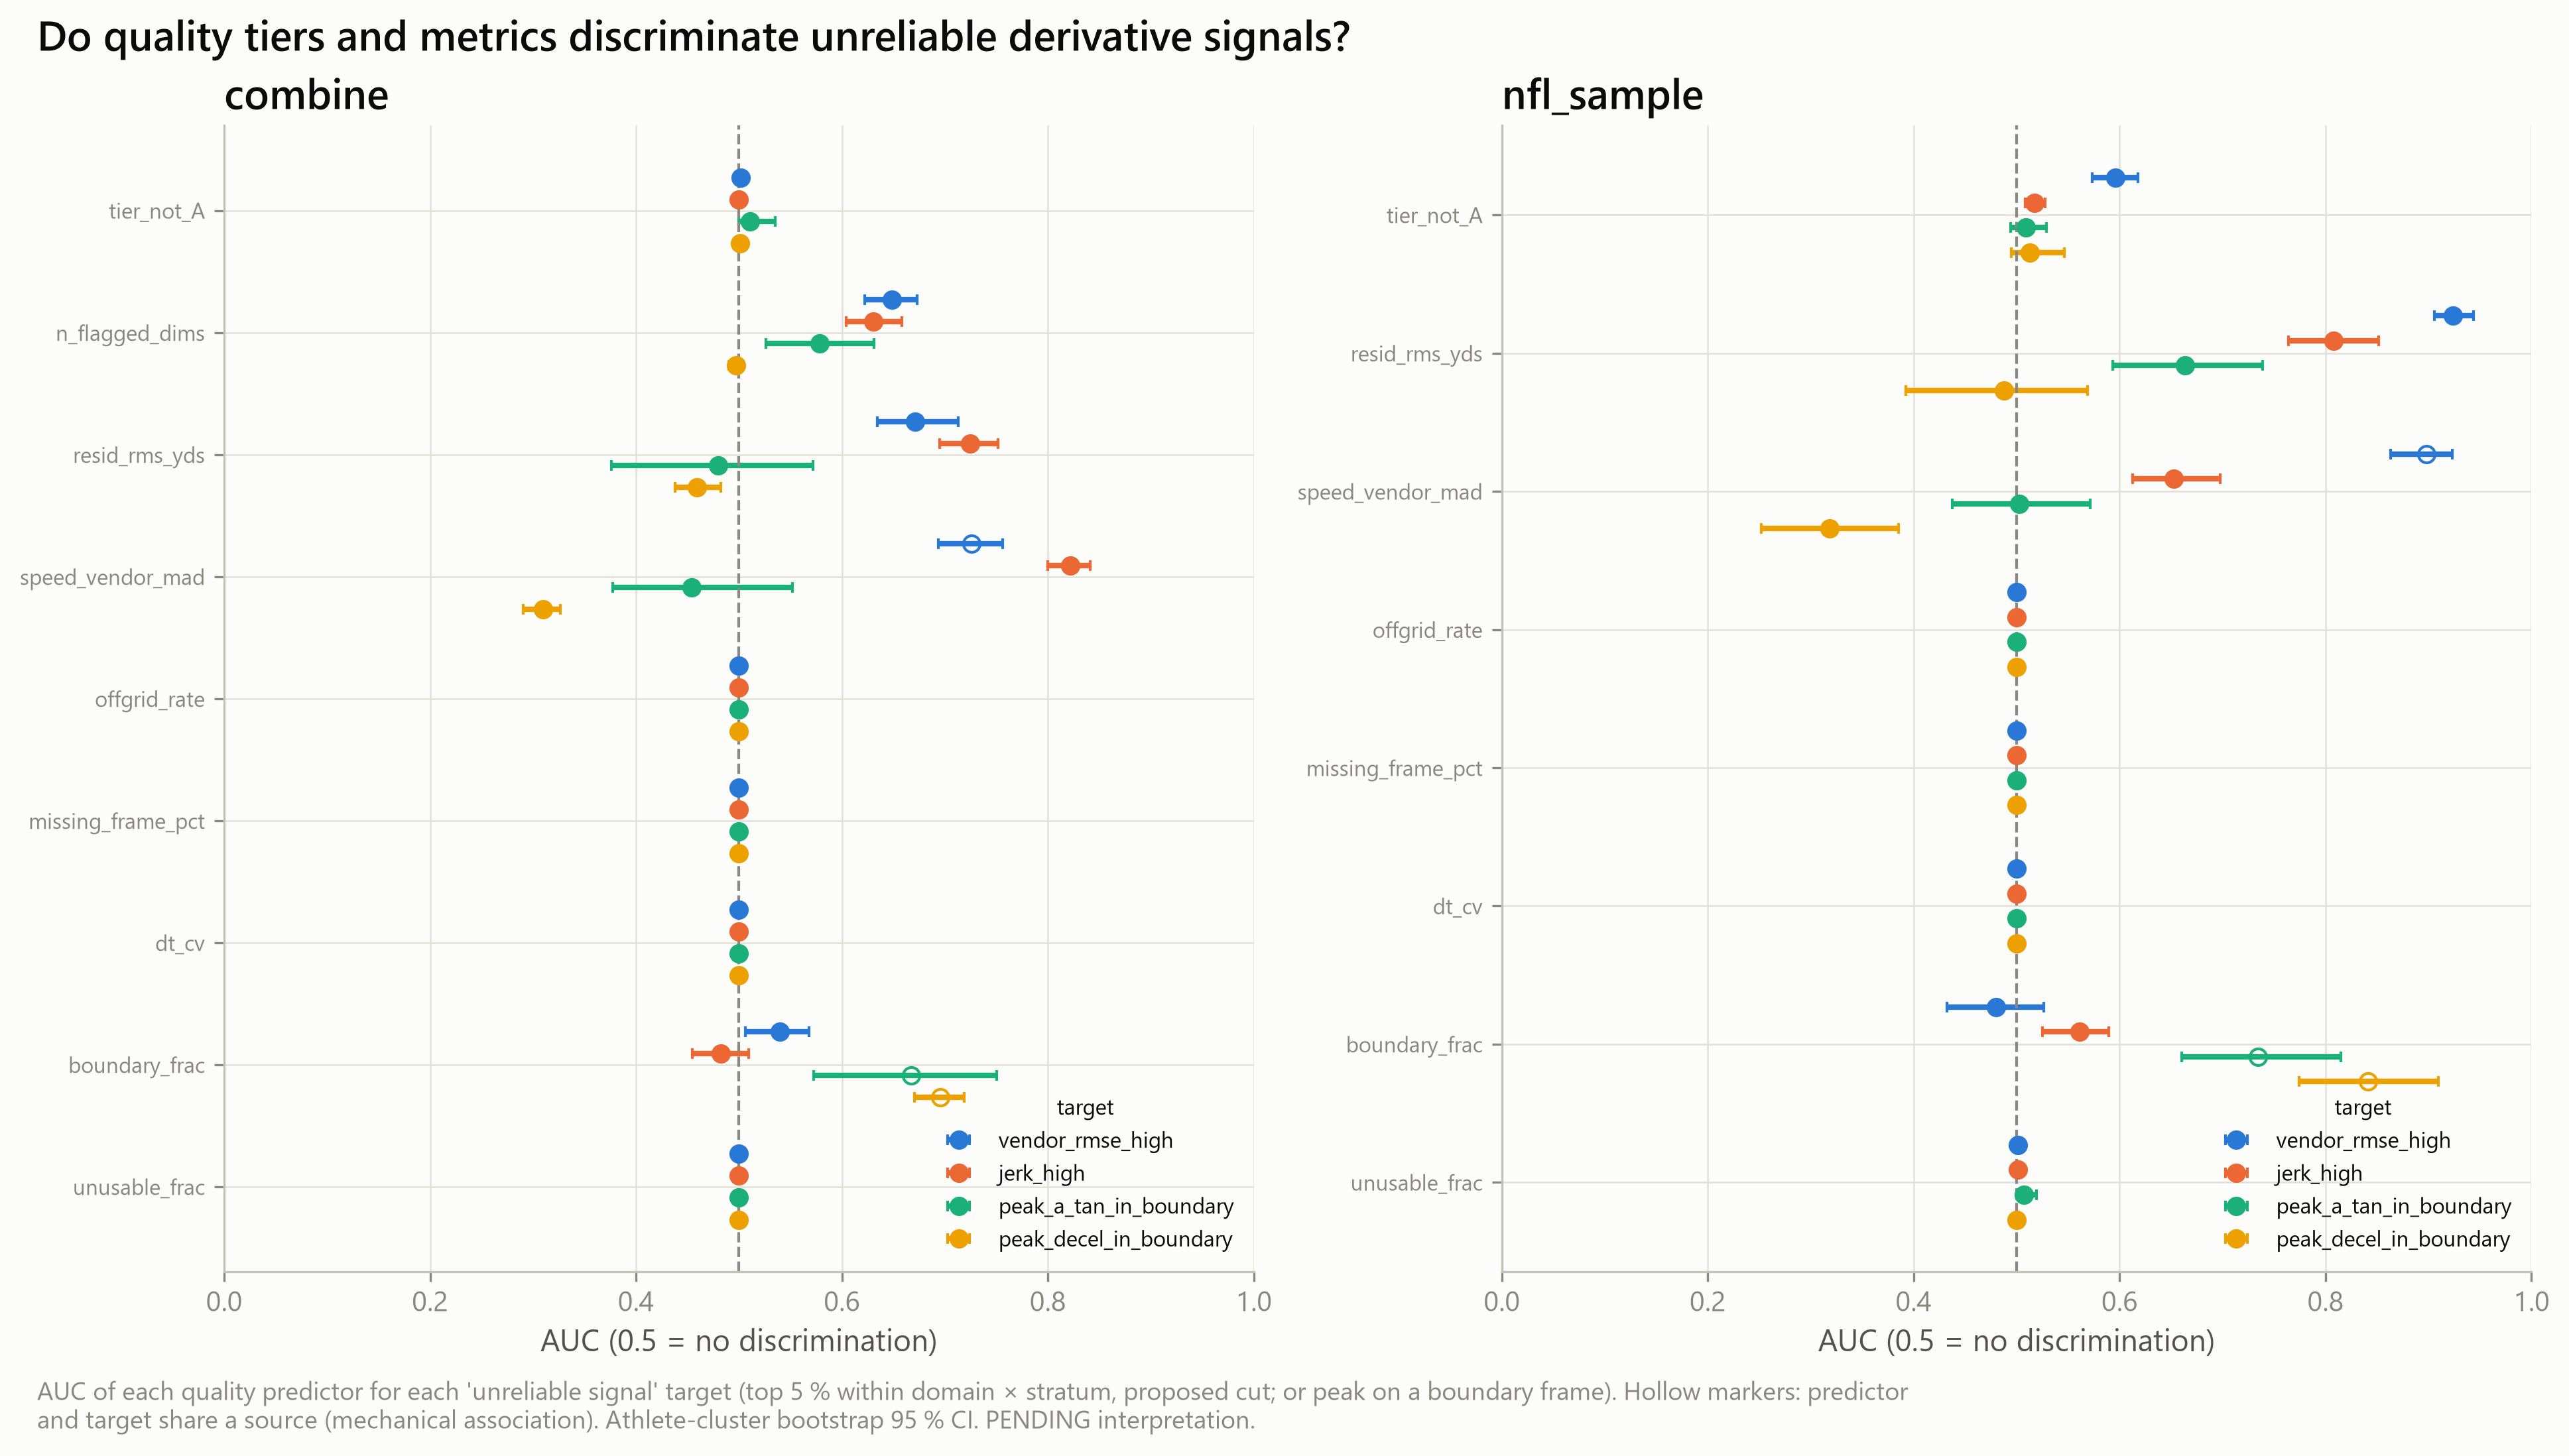

In [6]:
d = a3[A3.DISCRIM.name]
display(d.filter(~pl.col("shares_source")).sort("domain", "target", "auc", descending=[False, False, True]))
show_fig("A3", "A3_02_tier_discrimination")

In [7]:
display(a3[A3.SAMPLING.name])
assert a3[A3.SAMPLING.name]["n_heading_inconsistent"].sum() == 0, "heading null ≠ low speed somewhere — inspect"
show_fig("A3", "A3_03_roughness_by_cohort")

domain,cohort,stratum,n_trajectories,n_athletes,median_dt_cv,p95_dt_cv,share_offgrid_any,mean_missing_frame_pct,p95_missing_frame_pct,share_gap_break,share_jump_break,median_lowspeed_frac,n_heading_inconsistent,median_jerk_rms_interior,median_vendor_rmse
str,i64,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64
"""combine""",2023,"""FORTY_YARD_DASH""",262,138,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035714,1,3.182575,0.04106
"""combine""",2023,"""SHORT_SHUTTLE""",65,46,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.12766,0,9.215565,0.11708
"""combine""",2023,"""SKILL_DRILLS_DB""",312,35,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.034884,1,4.931366,0.04451
"""combine""",2023,"""SKILL_DRILLS_DL""",295,33,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.076923,0,6.471549,0.062639
"""combine""",2023,"""SKILL_DRILLS_LB""",37,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.078947,0,5.720412,0.05438
"""combine""",2023,"""SKILL_DRILLS_OL""",284,37,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2,0,5.821181,0.062685
"""combine""",2023,"""SKILL_DRILLS_TE""",97,12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035088,1,3.96978,0.040522
"""combine""",2023,"""SKILL_DRILLS_WR""",555,39,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.045977,0,5.786338,0.05325
"""combine""",2023,"""THREE_CONE_DRILL""",59,45,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.102564,0,10.04268,0.142959


AssertionError: heading null ≠ low speed somewhere — inspect

**Interpretation (fill after execution):**
- Boundary contamination: _which peak features / drills have observed ≫ expected? For the forty, separate true end-of-recording peaks (recording ends at peak speed) from edge artefacts using `*_boundary_rel`._
- Tier discrimination: _is `tier_not_A` informative (AUC CI excludes 0.5)? Which continuous metric discriminates best, ignoring shared-source pairs?_
- Cohort: _does the 2025 noise reduction (M1: ≈ ¼) show up in jerk RMS / vendor RMSE? Consequence for cross-cohort derivative features._
- Decision on G1 (signal validity): _…_

## C0 · Snap-anchored NFL windows

Anchors come from tracking event tags (`ball_snap`, release events). Kinematics are computed on whole trajectories in standardised coordinates and then windowed; pre-snap frames have their own window. Reload is lazy and never re-reads raw tracking.

92450 plays · 1253417 player-play × window rows
m11_nfl_anchor_coverage


season,season_type,n_plays,share_has_snap,share_multiple_snap_tags,share_snap_at_play_start,share_has_release,pre_snap_s_p05,…,pre_snap_s_p50,pre_snap_s_p75,pre_snap_s_p95,post_snap_s_p05,post_snap_s_p25,post_snap_s_p50,post_snap_s_p75,post_snap_s_p95
i64,str,i64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64
2023,"""REG""",25195,0.99996,0.000079,0.000079,0.997023,0.9,…,1.0,1.0,1.0,4.0,5.0,5.8,7.0,9.1
2024,"""REG""",32638,0.999969,0.000214,0.000214,0.994914,0.9,…,1.0,1.0,1.0,4.0,5.0,5.8,6.9,9.2
2025,"""REG""",34617,0.999884,0.000029,0.000318,0.987232,0.9,…,1.0,1.0,1.0,4.0,5.0,5.8,6.9,9.1


m11_nfl_release_timing


release_event,n_plays,snap_to_release_s_p05,snap_to_release_s_p25,snap_to_release_s_p50,snap_to_release_s_p75,snap_to_release_s_p95
str,i64,f64,f64,f64,f64,f64
"""pass_forward""",50439,1.5,2.1,2.6,3.3,5.0
"""handoff""",31367,1.0,1.2,1.3,1.4,1.6
"""run""",4920,0.9,1.9,3.4,4.7,6.4
"""qb_sack""",3199,3.1,3.9,4.6,5.3,6.9
"""qb_kneel""",1061,0.4,0.6,0.8,0.9,1.4
"""qb_strip_sack""",364,2.5,3.0,3.5,4.1,5.685
"""pass_shovel""",233,0.7,0.8,1.6,3.4,5.3
"""qb_spike""",184,0.3,0.4,0.5,0.6,0.9


m11_nfl_window_coverage


window,season,n_player_plays,n_athletes,share_features_valid,share_coverage_ok,share_censored_start,share_censored_end,share_truncated_by_play_end,share_in_player_play,mean_boundary_frac,share_speed_max_in_boundary,share_time_to_disp_defined
str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""post_0_1p5""",2023,39145,122,1.0,0.999923,0.0,0.000485,0.000485,0.989117,0.000699,0.001303,0.92561
"""post_0_1p5""",2024,86216,247,1.0,0.999965,0.0,0.000534,0.000534,0.990292,0.000766,0.001554,0.916454
"""post_0_1p5""",2025,125728,353,1.0,0.999952,0.0,0.000779,0.000779,0.992285,0.000827,0.001646,0.911969
"""post_0_3""",2023,39145,122,1.0,0.989143,0.0,0.013309,0.013309,0.989117,0.002234,0.0035,0.92561
"""post_0_3""",2024,86216,247,1.0,0.98912,0.0,0.013292,0.013292,0.990292,0.002267,0.00399,0.916454
"""post_0_3""",2025,125728,353,1.0,0.98768,0.0,0.014698,0.014698,0.992285,0.002524,0.004693,0.911969
"""post_snap_all""",2023,39145,122,1.0,1.0,0.0,0.0,0.0,0.989117,0.051854,0.030604,0.92561
"""post_snap_all""",2024,86216,247,1.0,1.0,0.0,0.000046,0.0,0.990292,0.051797,0.028197,0.916454
"""post_snap_all""",2025,125728,353,1.0,1.0,0.0,0.00004,0.0,0.992285,0.051964,0.03059,0.911969


m11_nfl_presnap_peak_share


position_group,side,n_player_plays,n_athletes,n_peak_pre_snap,share,wilson_lower,wilson_upper
str,str,i64,i64,i64,f64,f64,f64
"""DB""","""defense""",66675,95,707,0.010604,0.009854,0.01141
"""DB""","""offense""",27,1,0,0.0,0.0,0.124555
"""DL""","""defense""",52441,98,214,0.004081,0.00357,0.004664
"""DL""","""offense""",1,1,1,1.0,0.206549,1.0
"""OL""","""offense""",86307,91,74,0.000857,0.000683,0.001076
"""TE""","""offense""",7499,33,22,0.002934,0.001938,0.004438
"""TE""","""unknown""",632,31,11,0.017405,0.009746,0.030895
"""WR""","""offense""",35261,83,286,0.008111,0.007227,0.009102
"""WR""","""unknown""",1600,79,23,0.014375,0.009598,0.021479


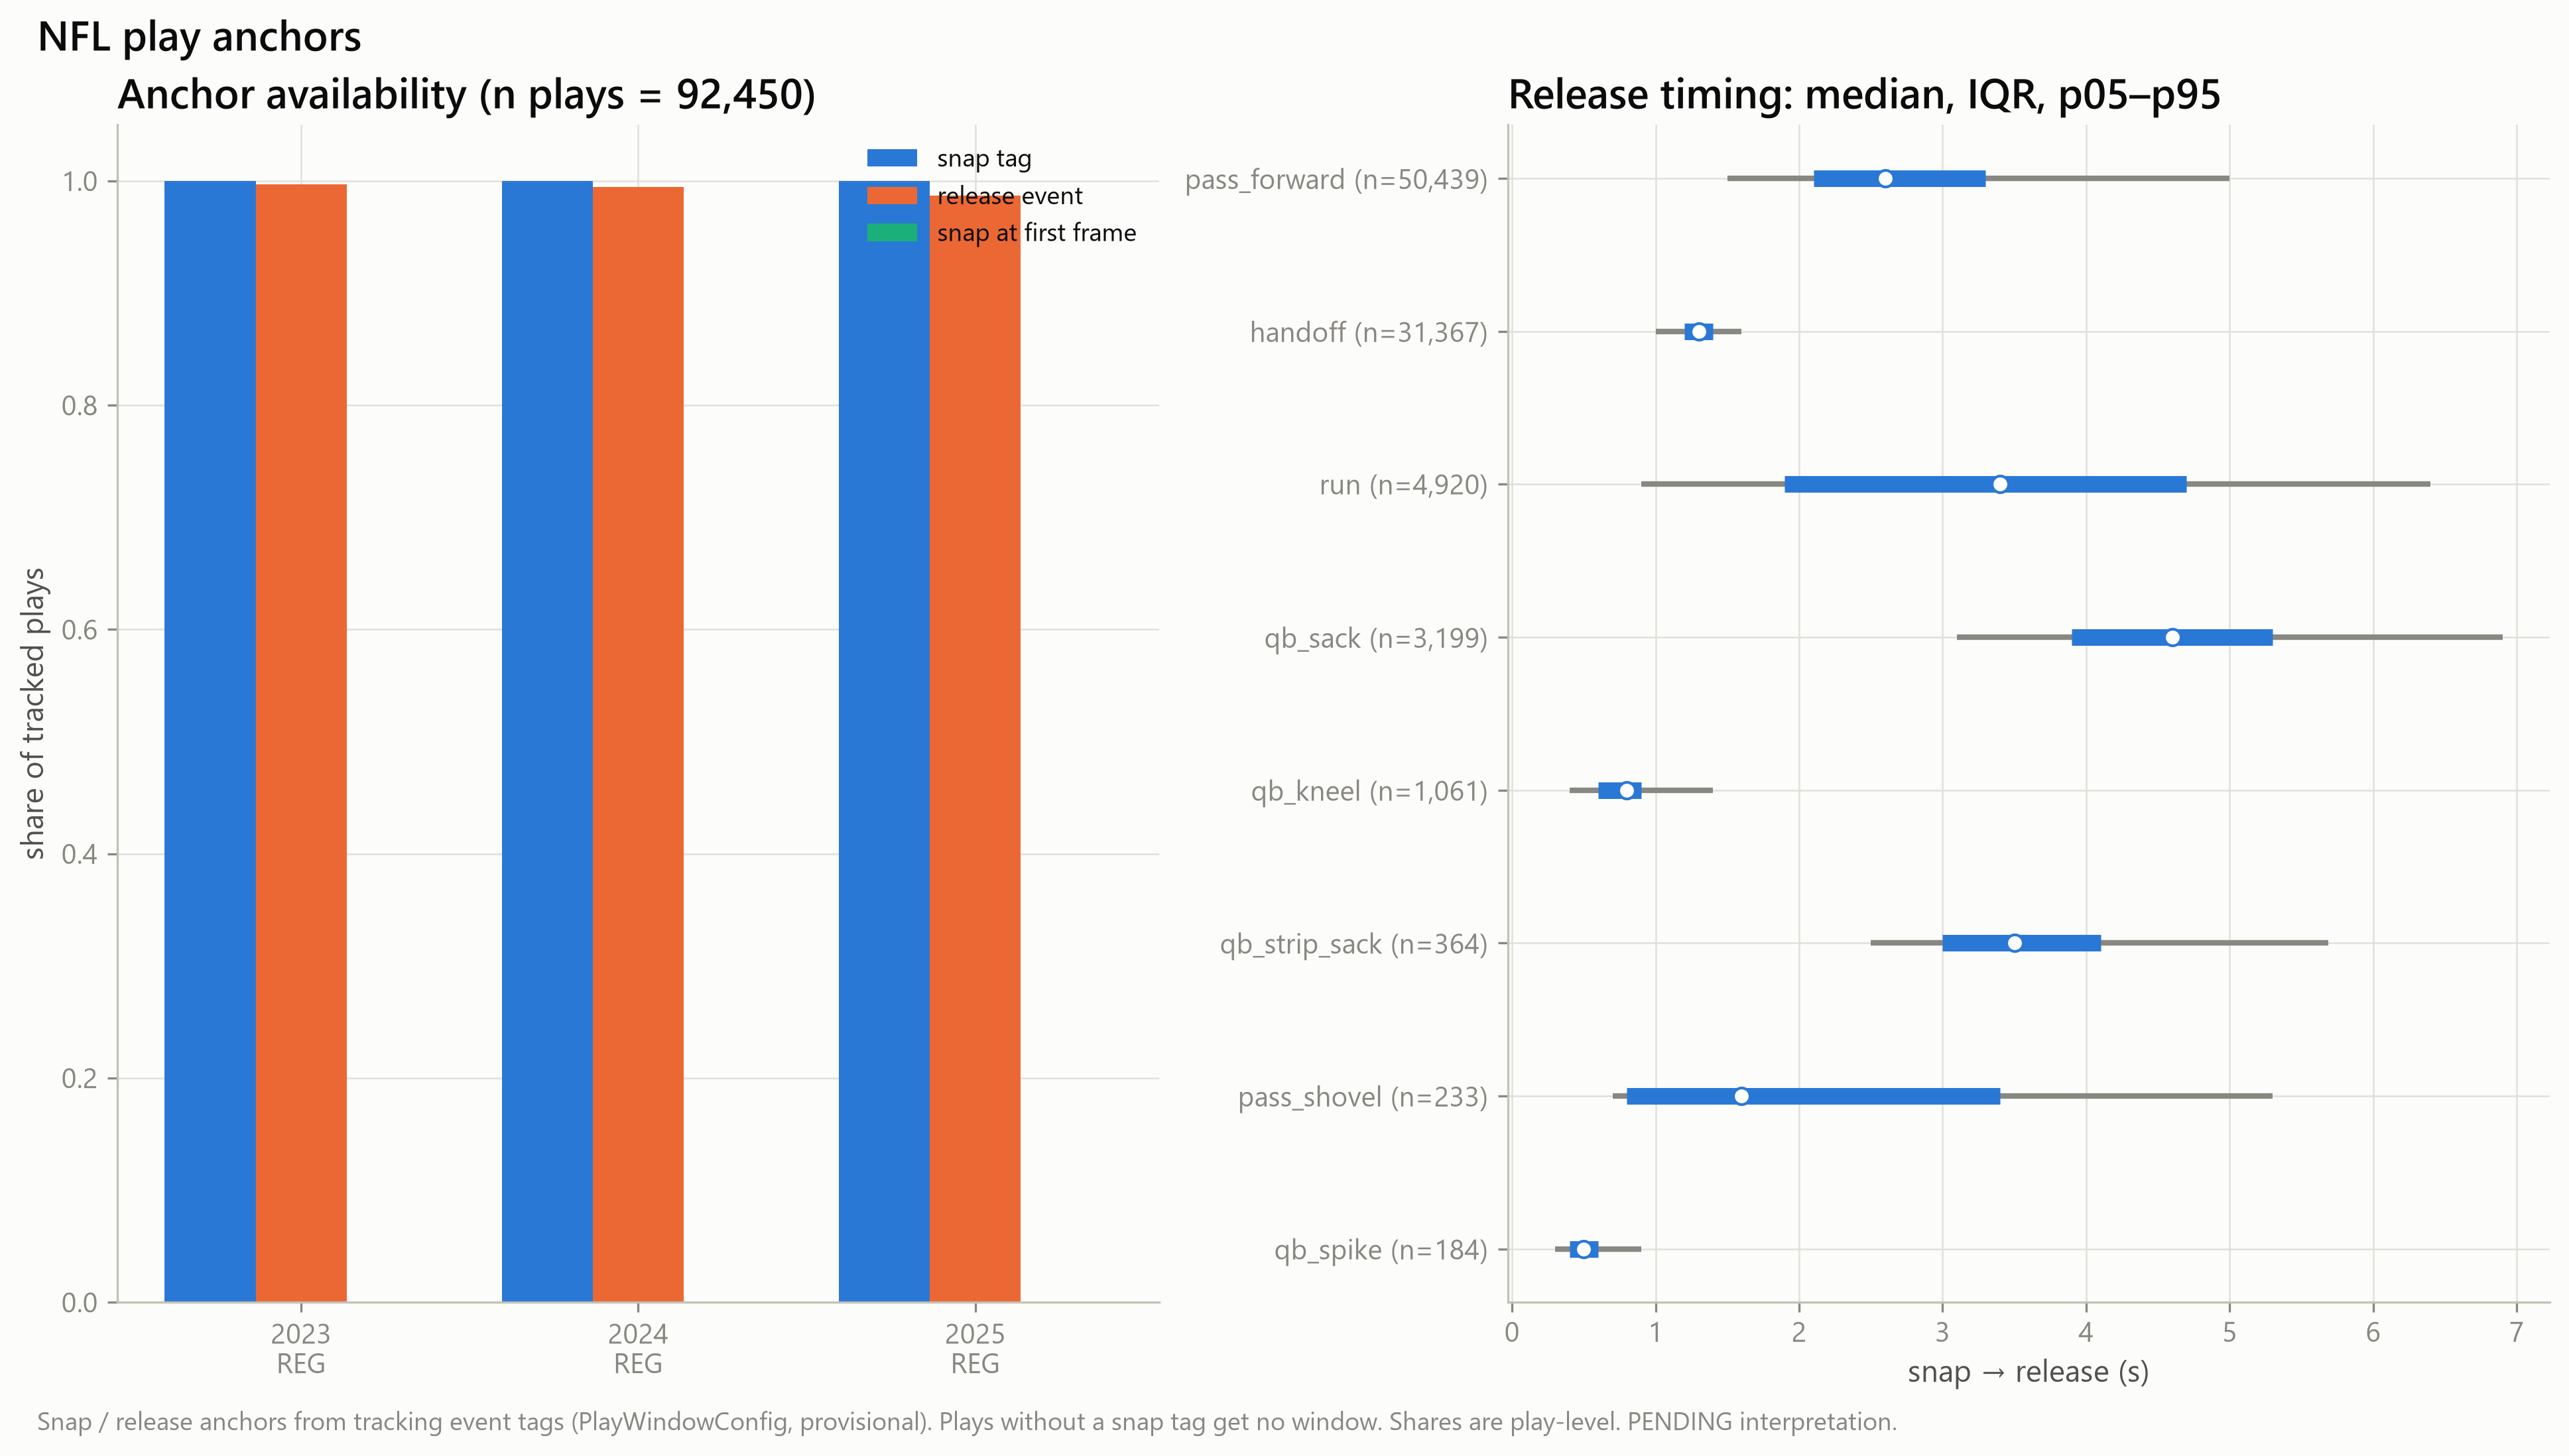

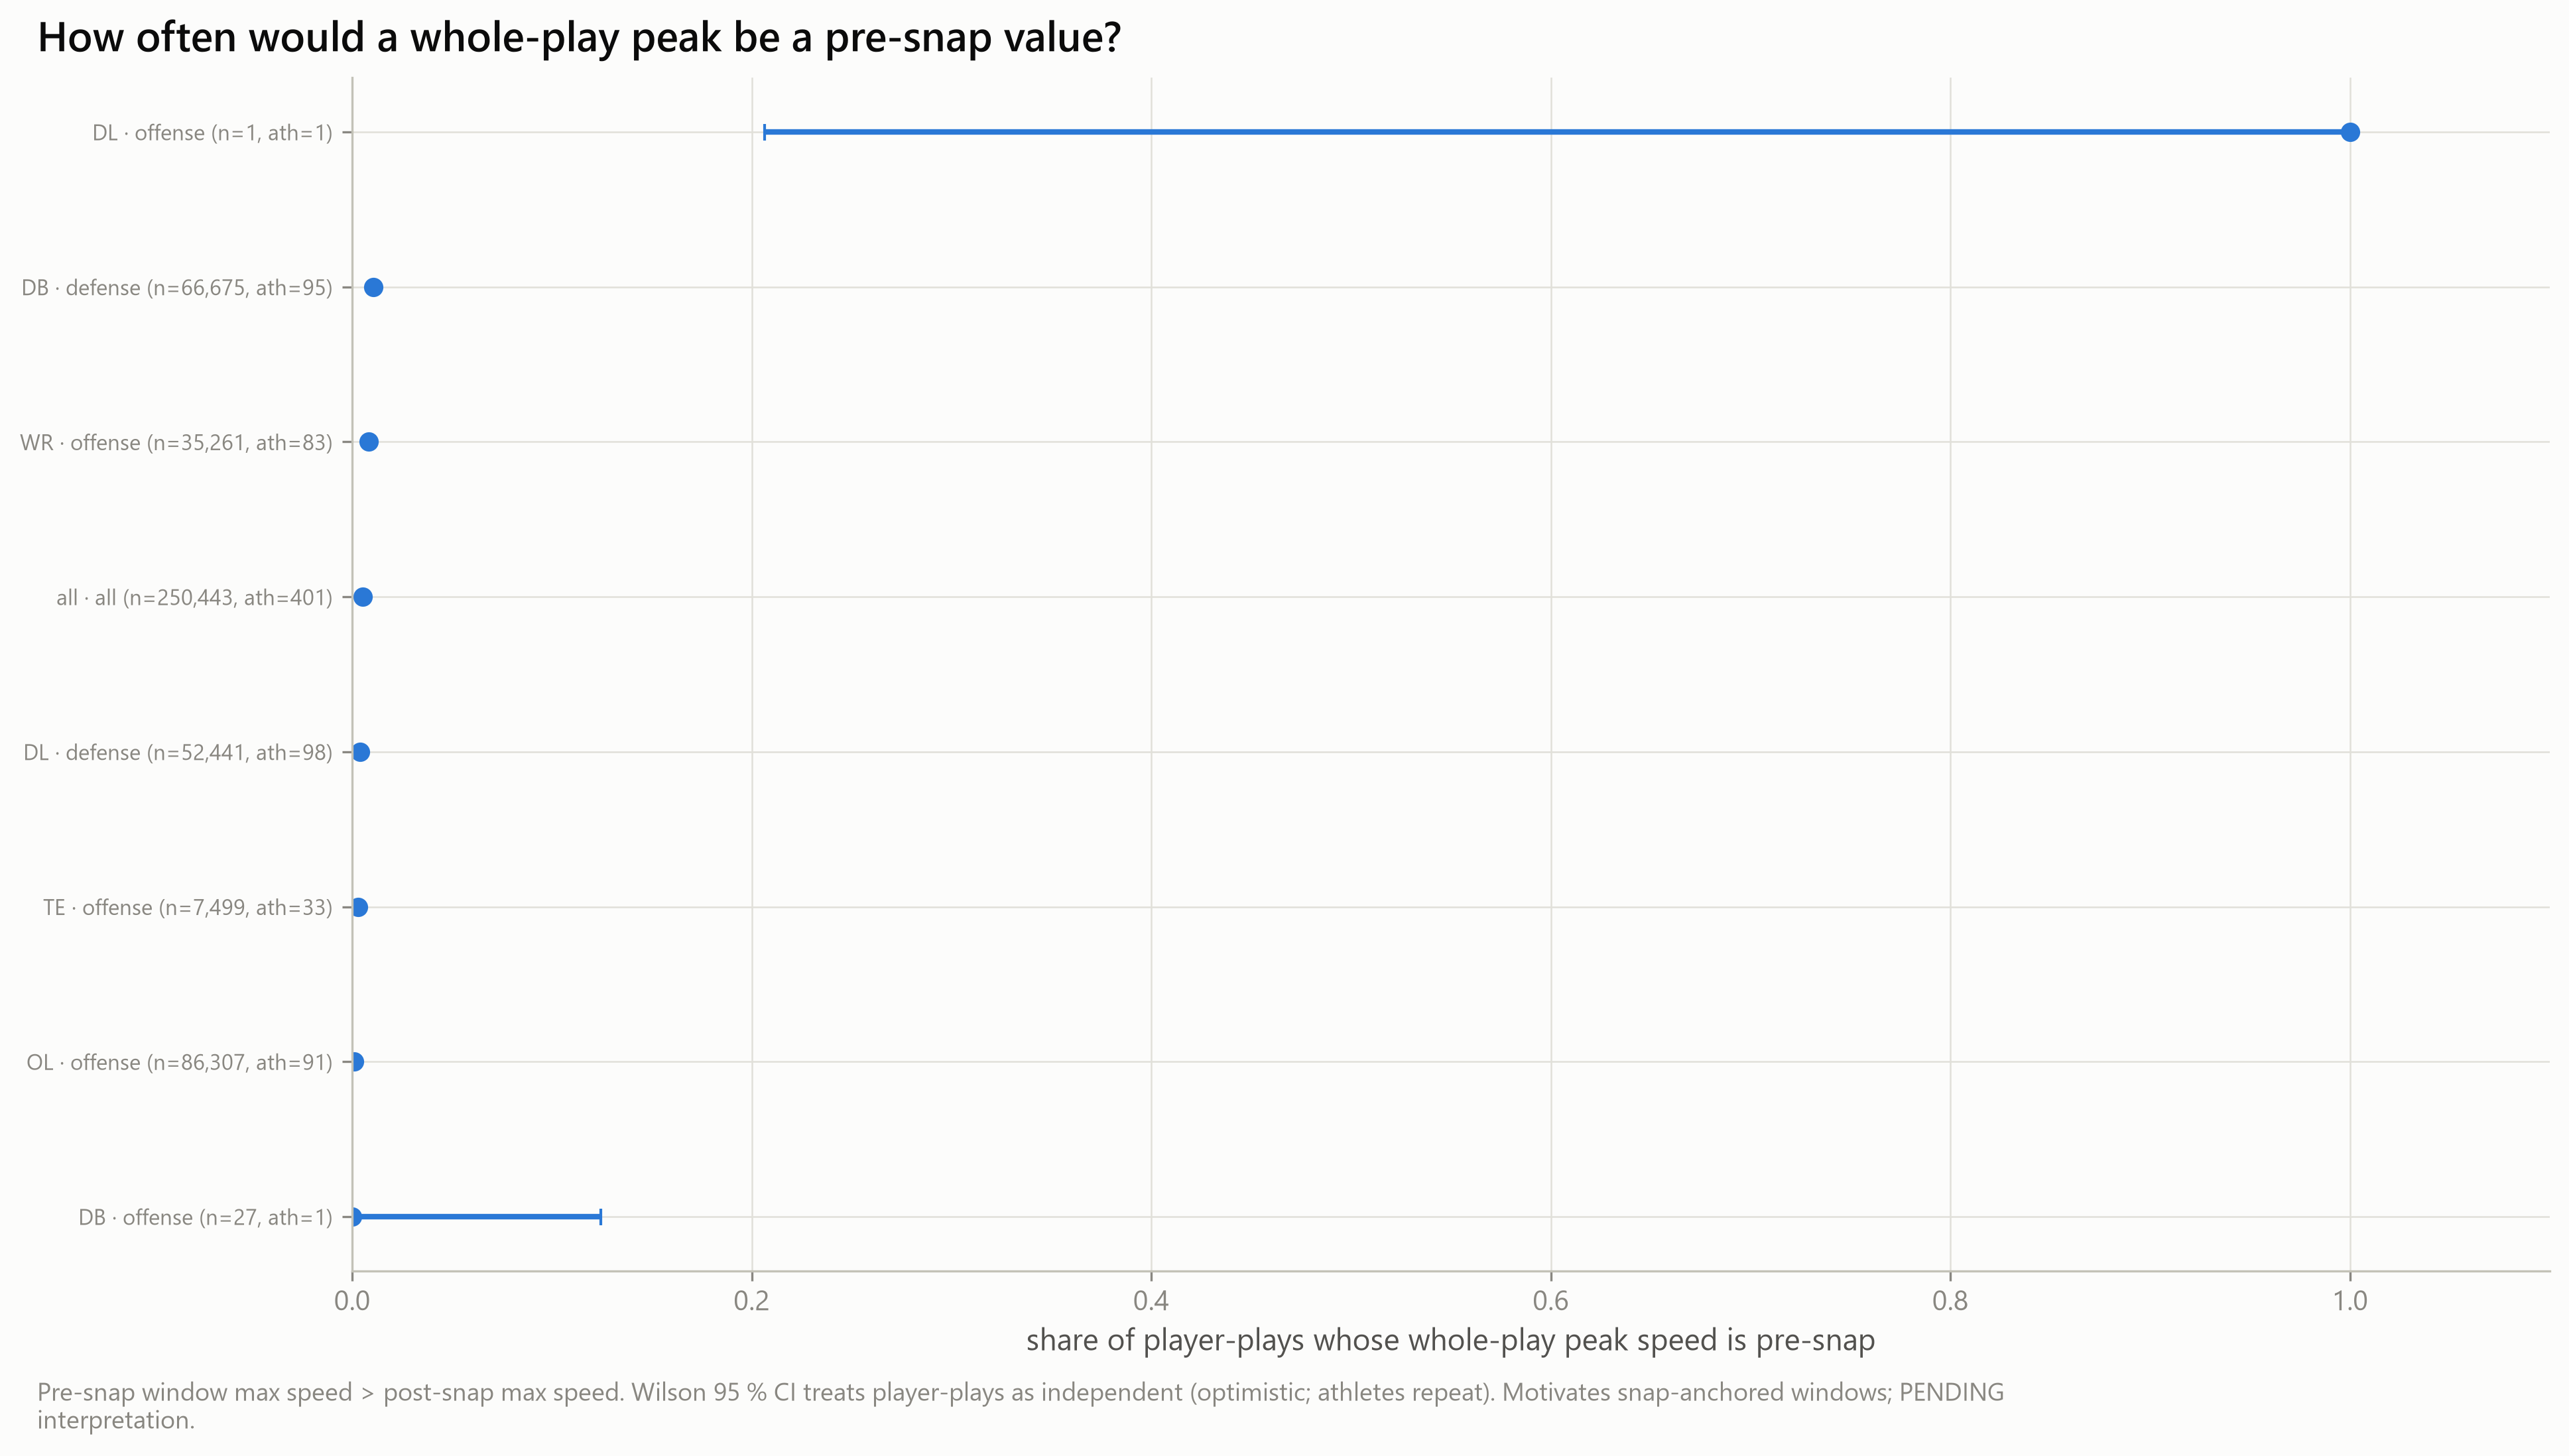

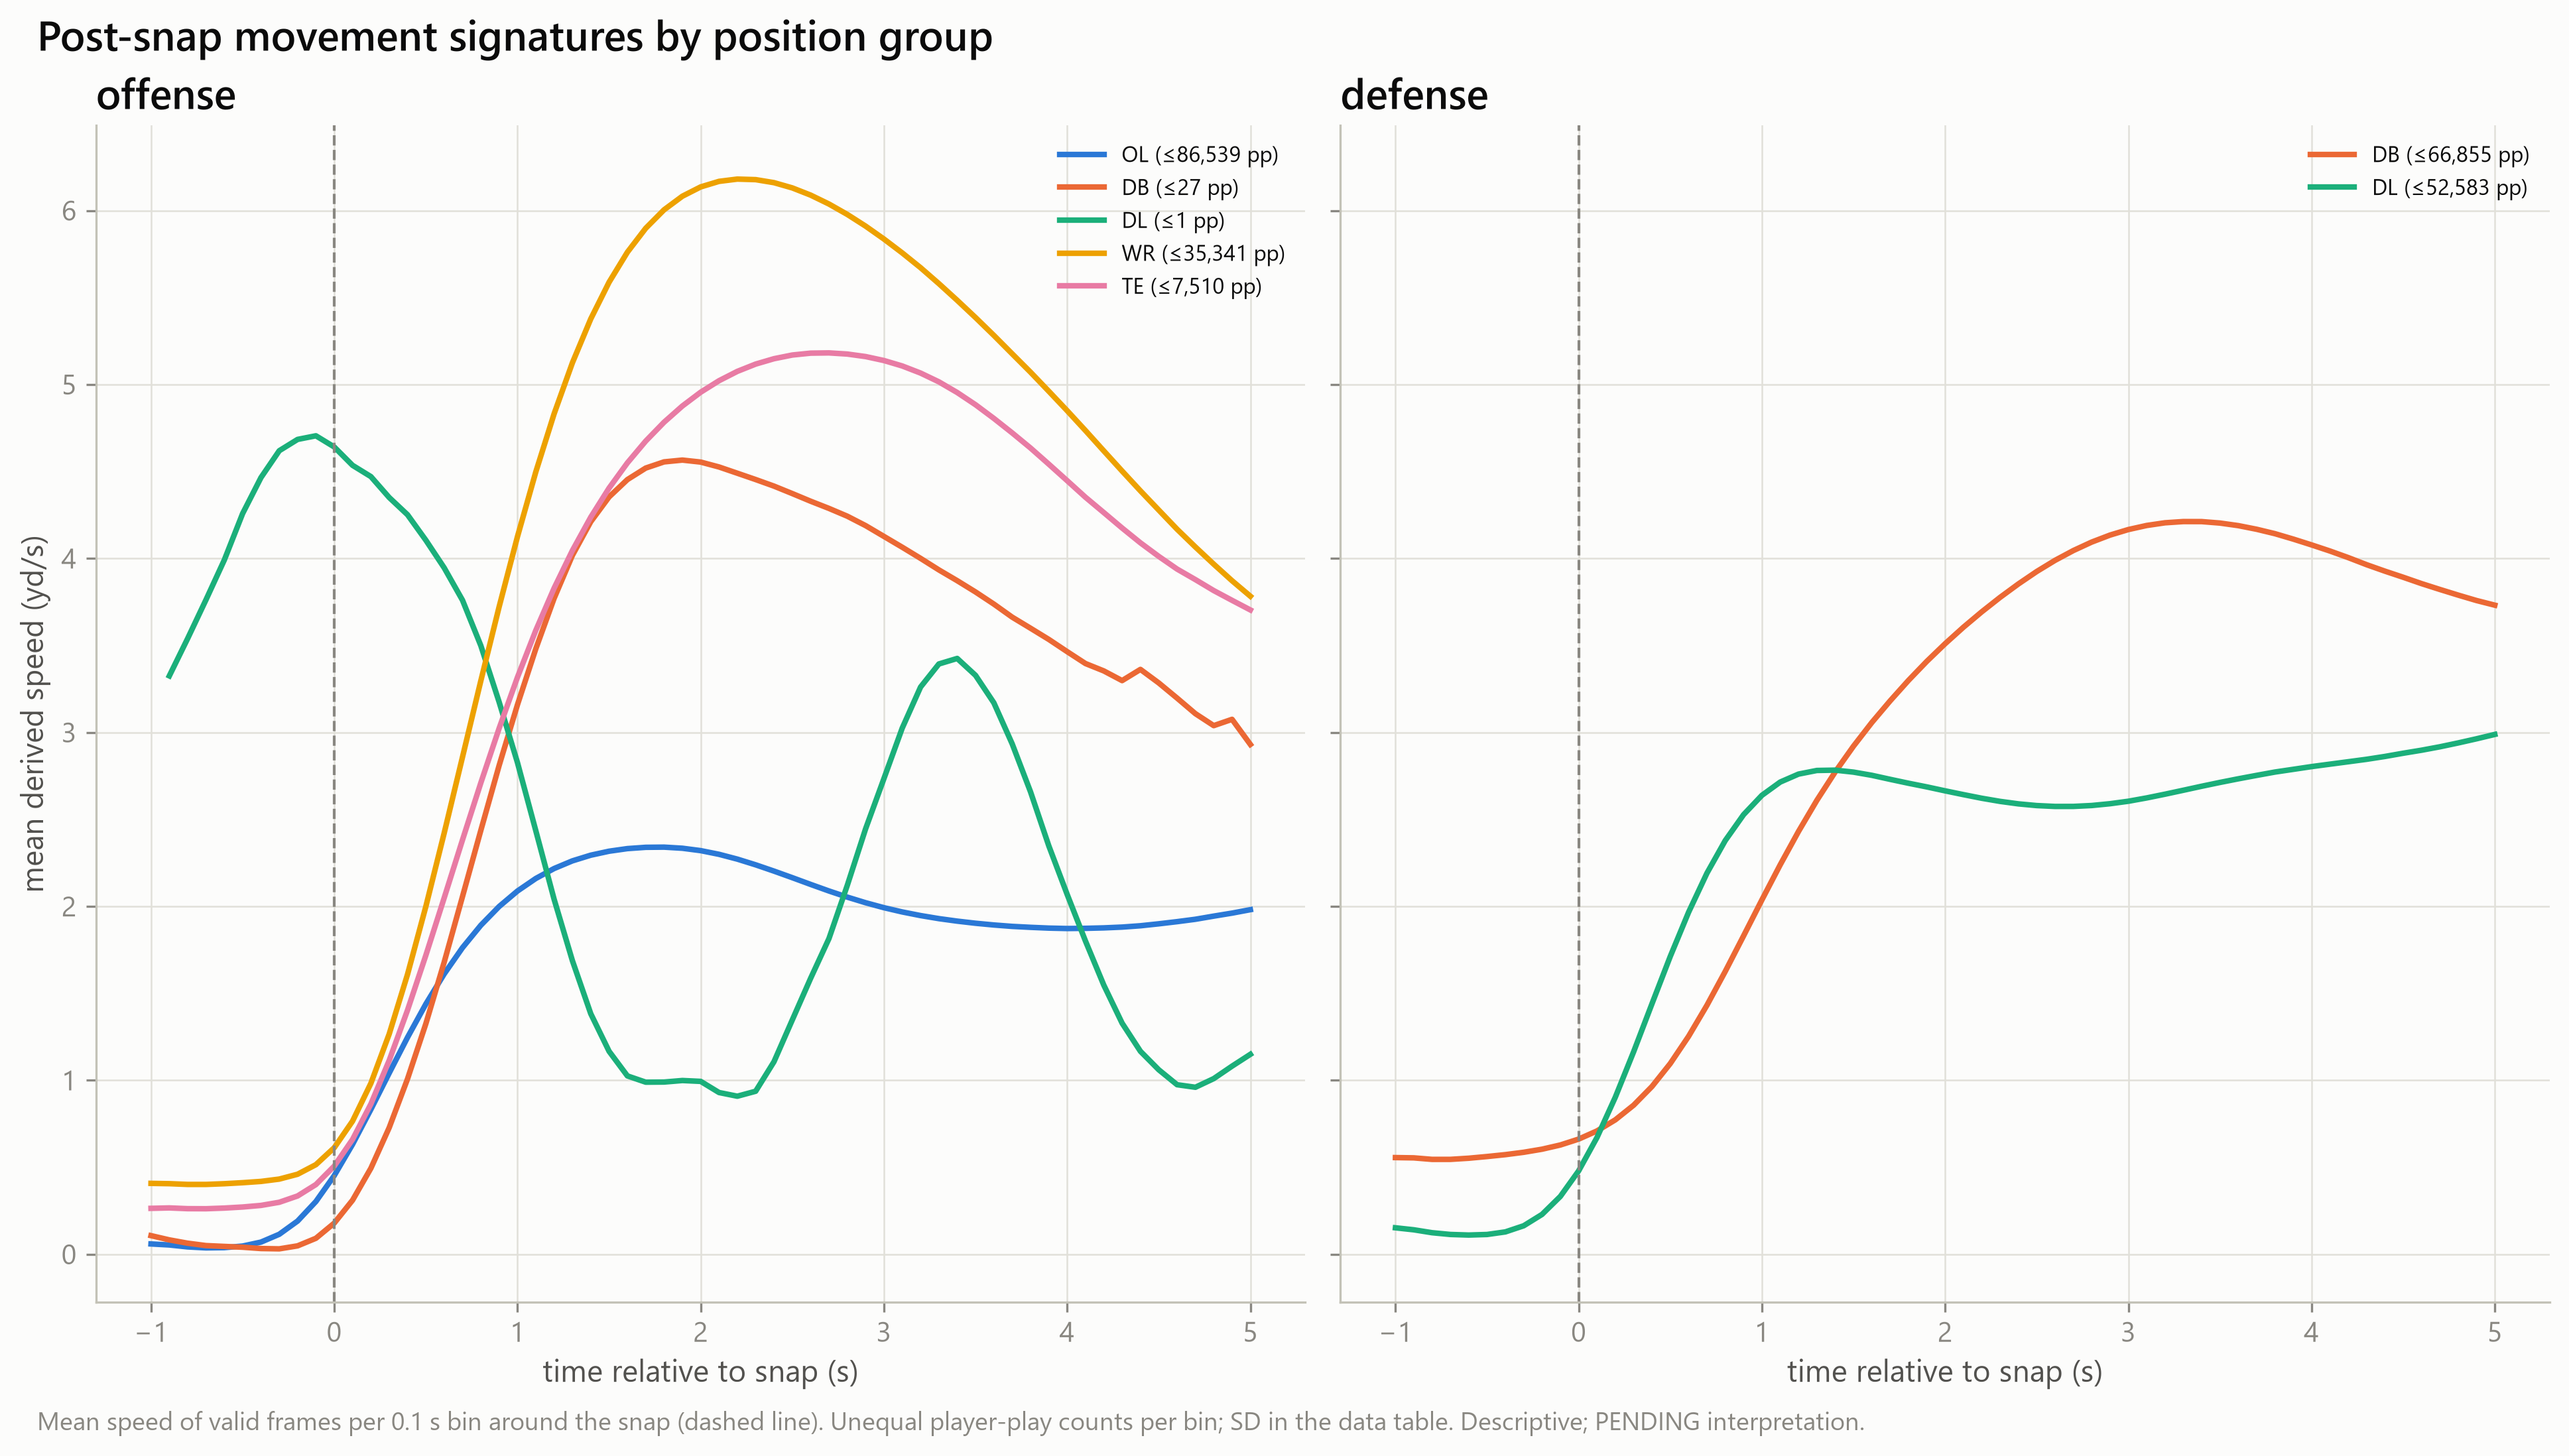

In [8]:
anchors = p03.load("nfl_play_anchors")
windows = p03.load("nfl_player_play_windows")
print(anchors.select(pl.len()).collect().item(), "plays ·", windows.select(pl.len()).collect().item(), "player-play × window rows")
for name in ("m11_nfl_anchor_coverage", "m11_nfl_release_timing", "m11_nfl_window_coverage", "m11_nfl_presnap_peak_share"):
    print(name)
    display(pl.read_parquet(p03.tables_dir / f"{name}.parquet"))
for fig in ("m11_nfl_anchor_coverage", "m11_nfl_presnap_peak_share", "m11_nfl_snap_speed_profile"):
    show_p03_fig(fig)

In [9]:
# Example reload: early post-snap features of valid, well-covered player-plays (no recomputation)
early = (windows.filter((pl.col("window") == "post_0_1p5") & pl.col("features_valid") & pl.col("coverage_ok"))
         .group_by("position_group", "side")
         .agg(pl.len().alias("n_player_plays"), pl.col("nfl_id").n_unique().alias("n_athletes"),
              pl.col("a_tan_sust_max").median(), pl.col("time_to_disp_s").median(), pl.col("speed_max").median())
         .sort("position_group", "side").collect())
display(early)

position_group,side,n_player_plays,n_athletes,a_tan_sust_max,time_to_disp_s,speed_max
str,str,u32,u32,f64,f64,f64
"""DB""","""defense""",66854,95,2.751728,1.0,2.969829
"""DB""","""offense""",27,1,4.573389,0.9,4.671539
"""DL""","""defense""",52579,98,3.078982,0.8,3.011957
"""DL""","""offense""",1,1,-0.970805,0.3,4.640913
"""OL""","""offense""",86532,91,2.360274,0.9,2.42932
"""TE""",null,632,31,3.395349,0.9,3.694818
"""TE""","""offense""",7510,33,4.110619,0.8,4.807105
"""WR""",null,1601,79,4.055584,0.9,4.299057
"""WR""","""offense""",35341,83,4.925084,0.8,5.878356


**Interpretation (fill after execution):**
- Anchor coverage: _share of plays with a snap tag; any `multiple_snap_tags` / `snap_at_play_start`; release availability by play type._
- Pre-snap peak share: _how often an M1 whole-play peak would have been a pre-snap value, by position — the quantitative case for snap anchoring._
- Speed profiles: _plausible post-snap signatures? (descriptive only)_
- These medians are **not** athlete rankings: opportunity (snaps, roles) is not yet controlled (Milestone 3).